# 12 — Which sky model matches the fitted 408 MHz sky along the TRIS ring?

**The question.** The model comparison (`model_comparison/`) fits a power law and a curved power
law to the SED at every TRIS ring sample. Haslam is **not** one of the fitted points, so each fit
*predicts* the 408 MHz sky seen through the TRIS beam. This notebook asks which existing 408 MHz sky
model agrees best with that prediction.

**What it does.**
1. **Fits:** reruns the power law and the curved power law at every ring sample with UltraNest,
   with the same data, error bars, priors and sampler settings as `run_comparison.py`
   (`model_comparison/config.yaml`), but keeping the posterior. The pivot is 408 MHz, so the
   predicted 408 MHz temperature is the amplitude A.
2. **Sky-model TODs:** builds each sky model at 408 MHz and beam-matches it to the TRIS beam at the
   ring pointings, exactly as the pipeline does for every map (`sed_prototype.Inputs.ring_tod`,
   `sed.tod_beam: beam_matched`; the same TODs as notebook 18).
3. **Compares:** χ² = Σ (T_model − A_fit)² / σ_A² over the ring samples, for every pair of sky model
   and fit. The lowest χ² wins.

**Temperatures** are Rayleigh–Jeans with the CMB removed, the convention of the SED fits.

**Rerun:** Restart & Run All. The fits and TODs are cached in `model_comparison/sky_models_408/cache/`;
delete that folder to rebuild them (about 15 minutes). Settings are in the next cell.

In [1]:
%matplotlib inline
import os
os.environ.setdefault("TQDM_DISABLE", "1")
import sys
import json
import logging
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
MC_DIR = REPO / "model_comparison"
CONFIG_PATH = MC_DIR / "config.yaml"
ERRORS_CSV = MC_DIR / "error_bars.csv"
OUT_DIR = MC_DIR / "sky_models_408"
CACHE_DIR = OUT_DIR / "cache"

# ---- fits ----
RUN_FITS = True            # run any fit missing from the cache (False: use the cache only)
SEED = 12345               # UltraNest draws from numpy's global RNG; seeded per ring sample
BEST_FIT = "maxlike"       # "maxlike" (maximum-likelihood point) or "median" (posterior median) of A

# ---- the Haslam map the corrections are applied to: the pipeline's target ----
HASLAM_FILE = "HASLAM_DESTRIPED_ONLY.fits"

# ---- Haslam corrections, as  E_corrected = scale * E + offset_k,  where E is the CMB-removed
# ---- RJ Haslam temperature.  None = not yet specified (the entry is skipped and reported).
T_CMB_RJ_408 = None        # filled in below from moonrunes.sky_maps.cmb_rj_k(408)
IRFAN_MONOPOLE_K = 8.9     # Irfan & Puglisi 2025: CMB + radio background + 21 cm (Wehus et al. 2017)
HASLAM_CORRECTIONS = {
    "Haslam, Carter correction": dict(
        scale=1.029, offset_k=0.91,
        ref="Carter et al. 2025 (B-GSM), arXiv:2504.04503: Eq. 2 T_cal = a T + b on CMB-subtracted "
            "maps, Table 2 a_408 = 1.029 ± 0.003, b_408 = +0.91 ± 0.05 K; one value for the whole sky"),
    "Haslam, Irfan correction": dict(
        scale=1.0, offset_k="irfan",   # = -(8.9 K - T_CMB,RJ(408)), set below
        ref="Irfan & Puglisi 2025, arXiv:2512.08522: T_sync = T_408 - 8.9 K (8.9 ± 1.3 K = CMB + "
            "radio background + 21 cm). Removes ~6.2 K more than the CMB alone"),
}

# ---- GINAN correction (McKay et al. 2025, arXiv:2509.11846): a correction to GSM2016,
# ---- T = (T_GSM16 - T_offset(f)) * F_scale(f), valid only for 60-350 MHz.  It is built at
# ---- GINAN_FREQ_MHZ and carried to 408 MHz with GSM2016's own per-pixel ratio
# ---- T_GSM16(408) / T_GSM16(GINAN_FREQ_MHZ).
GINAN_FREQ_MHZ = 350.0     # top of the correction's valid range

# ---- reading the evidence ----
CYG_A_RA = 299.9           # deg

# ---- Figure 1 only: spectral index used to scale the TRIS rings to 408 MHz, T * (408 / nu_eff)^beta
TRIS_BETA = -2.7

PL, CURVED = "power law", "curved power law"
FITS = [PL, CURVED]
# Fits in ink (black / grey); sky models in Okabe-Ito, colourblind-safe.
FIT_STYLE = {PL: dict(color="black", ls="-"), CURVED: dict(color="0.5", ls="--")}
SKY_STYLE = {
    "Haslam (uncorrected)":      dict(color="#E69F00", ls="-"),
    "Haslam, Carter correction": dict(color="#56B4E9", ls="-"),
    "Haslam, Irfan correction":  dict(color="#009E73", ls="-"),
    "GSM2008":                   dict(color="#0072B2", ls="--"),
    "GSM2016":                   dict(color="#D55E00", ls="--"),
    "GSM2016, GINAN correction": dict(color="#CC79A7", ls="--"),
    "LFSM":                      dict(color="#000000", ls=":"),
}

plt.rcParams.update({"figure.dpi": 110, "font.size": 12, "axes.titlesize": 13,
                     "axes.labelsize": 12, "legend.fontsize": 10, "figure.facecolor": "white"})
OUT_DIR.mkdir(exist_ok=True)
CACHE_DIR.mkdir(exist_ok=True)

def save(fig, name):
    # Save a figure as PNG in OUT_DIR, then show it inline.
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(f"saved {(OUT_DIR / f'{name}.png').relative_to(REPO)}")

## 1. Inputs

The repo's loader builds the ring data, the fitted surveys and the TRIS beam once (a few minutes).
It is only built if something is missing from the cache.

In [2]:
sys.dont_write_bytecode = True                   # leave no __pycache__ in model_comparison/
sys.path.insert(0, str(REPO / "src"))
sys.path.insert(0, str(MC_DIR))
from moonrunes import sky_maps
from moonrunes.sed_prototype import MIN_COVERAGE
from models import build_models, prior_transform
import run_comparison as rc                      # imported for its data helpers; main() is not run

with open(CONFIG_PATH) as f:
    cfg = yaml.safe_load(f)
assert cfg["data"]["route"] == "tod" and cfg["data"]["target_file"] == HASLAM_FILE, cfg["data"]
MODELS = build_models(cfg)
SCFG = cfg["sampler"]
PRIOR_KEY = json.dumps({n: cfg["priors"][n] for n in ("A_K", "beta", "C")}, sort_keys=True)
from moonrunes.config import load_config
from moonrunes.sed_prototype import tod_method_key
# How the ring TODs are made (run_config.yaml sed.tod_beam, beam-matched since 2026-10-27).  Cached results
# made from other TODs do not match it and are redone.
TOD_KEY = tod_method_key(load_config(REPO / "configs" / "run_config.yaml"))

T_CMB_RJ_408 = float(sky_maps.cmb_rj_k(408.0))
HASLAM_CORRECTIONS["Haslam, Irfan correction"]["offset_k"] = -(IRFAN_MONOPOLE_K - T_CMB_RJ_408)
print(f"T_CMB in RJ at 408 MHz: {T_CMB_RJ_408:.3f} K")
print(f"Irfan offset on the CMB-removed map: {HASLAM_CORRECTIONS['Haslam, Irfan correction']['offset_k']:+.3f} K")

_INP = None
def get_inputs():
    global _INP
    if _INP is None:
        from moonrunes.config import load_config
        from moonrunes.sed_prototype import Inputs
        print("building the TOD-route inputs (takes a few minutes)...")
        _INP = Inputs(load_config(REPO / "configs" / "run_config.yaml"), REPO / "res",
                      target_file=HASLAM_FILE, verbose=False)
    return _INP

ra_path = CACHE_DIR / "ring_ra.npy"
if not ra_path.exists():
    np.save(ra_path, np.asarray(get_inputs().ra, dtype=float))
RA = np.load(ra_path)
N_RING = RA.size
print(f"{N_RING} ring samples, RA {RA.min():.2f}-{RA.max():.2f} deg")

T_CMB in RJ at 408 MHz: 2.716 K
Irfan offset on the CMB-removed map: -6.184 K
120 ring samples, RA 0.00-357.00 deg


## 2. The fitted 408 MHz sky: power law and curved power law

Each ring sample is fitted with the data, error bars, priors and UltraNest settings of the model
comparison run. Results are cached per sample; a cached fit made with different priors is redone.

In [3]:
def fit_path(unit, model):
    return CACHE_DIR / "fits" / f"unit{unit:03d}__{model.replace(' ', '_')}.npz"

def run_nested(model, nu, t, s, seed):
    # The same likelihood and UltraNest call as run_comparison.log_evidence, keeping the posterior.
    import ultranest
    names, fn = MODELS[model]
    transform = prior_transform(names, cfg["priors"])
    norm = -np.sum(np.log(s * np.sqrt(2 * np.pi)))
    def loglike(params):
        r = (t - fn(nu, params)) / s
        return -0.5 * np.sum(r * r, axis=-1) + norm
    np.random.seed(seed)
    sampler = ultranest.ReactiveNestedSampler(names, loglike, transform, vectorized=True,
                                              log_dir=SCFG.get("log_dir"))
    logging.getLogger("ultranest").setLevel(logging.WARNING)
    res = sampler.run(min_num_live_points=int(SCFG["min_num_live_points"]), dlogz=float(SCFG["dlogz"]),
                      show_status=False, viz_callback=False)
    return dict(logz=res["logz"], logzerr=res["logzerr"], samples=res["samples"],
                maxpoint=np.asarray(res["maximum_likelihood"]["point"]), names=np.array(names))

def load_fit(unit, model):
    p = fit_path(unit, model)
    if not p.exists():
        return None
    z = np.load(p, allow_pickle=False)
    if str(z["prior_key"]) != PRIOR_KEY or "tod_key" not in z.files or str(z["tod_key"]) != TOD_KEY:
        return None                                  # made with other priors or other ring TODs: redo
    return {k: z[k] for k in z.files}

fits = {m: {} for m in FITS}
missing = [(u, m) for u in range(N_RING) for m in FITS if load_fit(u, m) is None]
if missing and RUN_FITS:
    (CACHE_DIR / "fits").mkdir(exist_ok=True)
    errors = rc.read_error_bars(ERRORS_CSV)
    need = {u for u, _ in missing}
    print(f"fitting {len(missing)} (sample, model) pairs...")
    for uid, _, pts in rc.tod_units(get_inputs(), errors):
        if uid not in need:
            continue
        pts = rc.usable(pts)
        if len(pts) < int(cfg["data"]["min_points"]):
            continue
        nu, t, s = (np.array([q[i] for q in pts], dtype=float) for i in (1, 2, 3))
        for m in FITS:
            if (uid, m) in missing:
                r = run_nested(m, nu, t, s, SEED + uid)
                np.savez(fit_path(uid, m), **r, nu=nu, t=t, s=s, keys=np.array([q[0] for q in pts]),
                         prior_key=PRIOR_KEY, tod_key=TOD_KEY)
for u in range(N_RING):
    for m in FITS:
        r = load_fit(u, m)
        if r is not None:
            fits[m][u] = r

A_best, A_sig = {}, {}
for m in FITS:
    A_best[m], A_sig[m] = np.full(N_RING, np.nan), np.full(N_RING, np.nan)
    for u, r in fits[m].items():
        iA = list(map(str, r["names"])).index("A_K")
        a = r["samples"][:, iA]
        A_best[m][u] = float(r["maxpoint"][iA]) if BEST_FIT == "maxlike" else float(np.median(a))
        A_sig[m][u] = float(np.std(a))
    print(f"{m:<18}: {len(fits[m])} samples fitted;  A(408) median {np.nanmedian(A_best[m]):.2f} K, "
          f"σ_A median {np.nanmedian(A_sig[m]):.2f} K ({100 * np.nanmedian(A_sig[m] / A_best[m]):.1f}%)")

power law         : 120 samples fitted;  A(408) median 32.13 K, σ_A median 0.17 K (0.5%)
curved power law  : 120 samples fitted;  A(408) median 35.67 K, σ_A median 2.19 K (6.3%)


## 3. Sky-model TODs at 408 MHz

GSM2008, GSM2016 and LFSM come from `pygdsm`, without the CMB, in Rayleigh–Jeans K. The Haslam
corrections (Carter, Irfan) are applied to the pipeline's destriped Haslam map before it is observed.
The GINAN correction applies to GSM2016 and is valid only up to 350 MHz, so it is built at 350 MHz
and carried to 408 MHz with GSM2016's own ratio T(408)/T(350) in each pixel. Every map is
beam-matched to the TRIS beam at the ring pointings with the pipeline's own call
(`Inputs.ring_tod`): the TRIS cut beam with the map's own beam taken out. The native beams of the
`pygdsm` models are those of notebook 18 (GSM2008 1°, GSM2016 48′, LFSM 5.1°); the Haslam maps use
Haslam's 56′.

In [4]:
# Native beams (FWHM, deg) of the pygdsm sky models, for the beam matching (as notebook 18).
MODEL_NATIVE_FWHM = {"GSM2008": 1.0, "GSM2016": 0.8, "GSM2016, GINAN correction": 0.8, "LFSM": 5.1}

def observe_full_sky(sky, frame, native_fwhm_deg):
    # TRIS ring TOD of a full-sky map, with sed_prototype.Inputs' own code (sed.tod_beam).
    import healpy as hp
    m = dict(sky=np.asarray(sky, dtype=float), nside=hp.npix2nside(len(sky)), frame=frame,
             fwhm_deg=float(native_fwhm_deg))
    return get_inputs().ring_tod(m)

def gsm_maps():
    # name -> CMB-removed RJ map (galactic) at 408 MHz
    from pygdsm import GlobalSkyModel, GlobalSkyModel16, LowFrequencySkyModel
    from pygdsm.mckay25 import generate_mckay25_correction, T_CMB
    g16 = GlobalSkyModel16(freq_unit="MHz", data_unit="TRJ", include_cmb=False)
    g16_408 = np.array(g16.generate(408.0), dtype=float)
    g16_lo = np.array(g16.generate(GINAN_FREQ_MHZ), dtype=float)
    # McKay et al. 2025 applied as pygdsm's McKaySkyModel does: GSM2016 with the CMB, in T_CMB units,
    # (T - T_offset) * F_scale, then the CMB removed.  Done here because McKaySkyModel's range check
    # rejects 350 MHz itself (350 MHz -> 0.35000000000000003 GHz > 0.35).
    off, scl = generate_mckay25_correction(np.array([GINAN_FREQ_MHZ / 1e3]))
    g16_cmb = np.array(GlobalSkyModel16(freq_unit="MHz", data_unit="TCMB", include_cmb=True).generate(GINAN_FREQ_MHZ),
                       dtype=float)
    ginan_lo = (g16_cmb - off[0]) * scl[0] - T_CMB
    print(f"GINAN correction at {GINAN_FREQ_MHZ:g} MHz: T_offset = {off[0]:.2f} K, F_scale = {scl[0]:.3f}; "
          f"GSM2016 ratio 408/{GINAN_FREQ_MHZ:g} MHz: median {np.median(g16_408 / g16_lo):.3f}")
    return {
        "GSM2008": GlobalSkyModel(freq_unit="MHz", include_cmb=False).generate(408.0),
        "GSM2016": g16_408,
        "GSM2016, GINAN correction": ginan_lo * g16_408 / g16_lo,
        "LFSM":    LowFrequencySkyModel(freq_unit="MHz", include_cmb=False).generate(408.0),
    }

def haslam_excess_map():
    inp = get_inputs()
    m = inp.target
    assert m["file"] == HASLAM_FILE
    return np.asarray(sky_maps.rj_excess(m["sky"], m), dtype=float), m["frame"]

SKY_SOURCES = {
    "Haslam (uncorrected)":      "Remazeilles et al. 2015 destriped (not desourced) Haslam, res/" + HASLAM_FILE,
    "GSM2008":                   "de Oliveira-Costa et al. 2008, pygdsm GlobalSkyModel, include_cmb=False",
    "GSM2016":                   "Zheng et al. 2017, pygdsm GlobalSkyModel16, TRJ, include_cmb=False",
    "LFSM":                      "Dowell et al. 2017, pygdsm LowFrequencySkyModel, include_cmb=False",
    "GSM2016, GINAN correction": "McKay et al. 2025 (GINAN receiver), arXiv:2509.11846 v3 coefficients via pygdsm "
                                 "McKaySkyModel at 350 MHz, x GSM2016 ratio 408/350 per pixel",
} | {k: v["ref"] for k, v in HASLAM_CORRECTIONS.items()}

tod_path = CACHE_DIR / "sky_tods.npz"
key_path = CACHE_DIR / "sky_tods_key.json"
corr_key = json.dumps({"corrections": {k: [v["scale"], v["offset_k"]] for k, v in HASLAM_CORRECTIONS.items()},
                       "models": list(SKY_STYLE), "ginan_freq_mhz": GINAN_FREQ_MHZ,
                       "native_fwhm": MODEL_NATIVE_FWHM, "tod_key": TOD_KEY}, sort_keys=True)
if tod_path.exists() and key_path.exists() and key_path.read_text() == corr_key:
    z = np.load(tod_path, allow_pickle=False)
    SKY_TOD = {str(n): (z[f"tod_{i}"], z[f"cov_{i}"]) for i, n in enumerate(z["names"])}
    print("sky-model TODs loaded from the cache")
else:
    SKY_TOD = {}
    e_map, frame = haslam_excess_map()
    h_fwhm = float(get_inputs().target["fwhm_deg"])           # Haslam's 56'
    SKY_TOD["Haslam (uncorrected)"] = observe_full_sky(e_map, frame, h_fwhm)
    for name, c in HASLAM_CORRECTIONS.items():
        if c["scale"] is None or c["offset_k"] is None:
            continue
        SKY_TOD[name] = observe_full_sky(c["scale"] * e_map + c["offset_k"], frame, h_fwhm)
    for name, sky in gsm_maps().items():
        SKY_TOD[name] = observe_full_sky(sky, "G", MODEL_NATIVE_FWHM[name])
    names = list(SKY_TOD)
    np.savez(tod_path, names=np.array(names),
             **{f"tod_{i}": SKY_TOD[n][0] for i, n in enumerate(names)},
             **{f"cov_{i}": SKY_TOD[n][1] for i, n in enumerate(names)})
    key_path.write_text(corr_key)

skipped = [k for k, v in HASLAM_CORRECTIONS.items() if v["scale"] is None or v["offset_k"] is None]
for k in skipped:
    print(f"!! SKIPPED: {k} -- scale/offset not specified in the settings cell")

# Check: the beam is normalised, so a corrected map's TOD must equal scale * TOD + offset.
h = SKY_TOD["Haslam (uncorrected)"][0]
for name, c in HASLAM_CORRECTIONS.items():
    if name in SKY_TOD:
        dev = np.nanmax(np.abs(SKY_TOD[name][0] - (c["scale"] * h + c["offset_k"])))
        print(f"linearity check {name}: max |TOD - (a TOD_H + b)| = {dev:.2e} K")

SKY_NAMES = [n for n in SKY_STYLE if n in SKY_TOD]
T_SKY = {n: np.where(SKY_TOD[n][1] >= MIN_COVERAGE, SKY_TOD[n][0], np.nan) for n in SKY_NAMES}
print("\n" + pd.DataFrame({"source": [SKY_SOURCES[n] for n in SKY_NAMES],
                          "ring mean [K]": [np.nanmean(T_SKY[n]) for n in SKY_NAMES]},
                         index=SKY_NAMES).round(2).to_string())

sky-model TODs loaded from the cache
linearity check Haslam, Carter correction: max |TOD - (a TOD_H + b)| = 6.50e-13 K
linearity check Haslam, Irfan correction: max |TOD - (a TOD_H + b)| = 4.33e-13 K

                                                                                                                                                                                                   source  ring mean [K]
Haslam (uncorrected)                                                                                             Remazeilles et al. 2015 destriped (not desourced) Haslam, res/HASLAM_DESTRIPED_ONLY.fits          28.38
Haslam, Carter correction  Carter et al. 2025 (B-GSM), arXiv:2504.04503: Eq. 2 T_cal = a T + b on CMB-subtracted maps, Table 2 a_408 = 1.029 ± 0.003, b_408 = +0.91 ± 0.05 K; one value for the whole sky          30.11
Haslam, Irfan correction                            Irfan & Puglisi 2025, arXiv:2512.08522: T_sync = T_408 - 8.9 K (8.9 ± 1.3 K = CMB + radio backgr

### Figure 1 — the fitted 408 MHz sky and the sky models along the ring
The black and grey lines are the 408 MHz temperatures the power law and the curved power law predict
from the other surveys, with their 1σ bands. The coloured lines are each sky model observed through
the TRIS beam. The markers are the measured TRIS rings at 600 and 820 MHz, scaled to 408 MHz with a fixed
spectral index (`TRIS_BETA`, −2.7), for display only; they play no part in the χ².

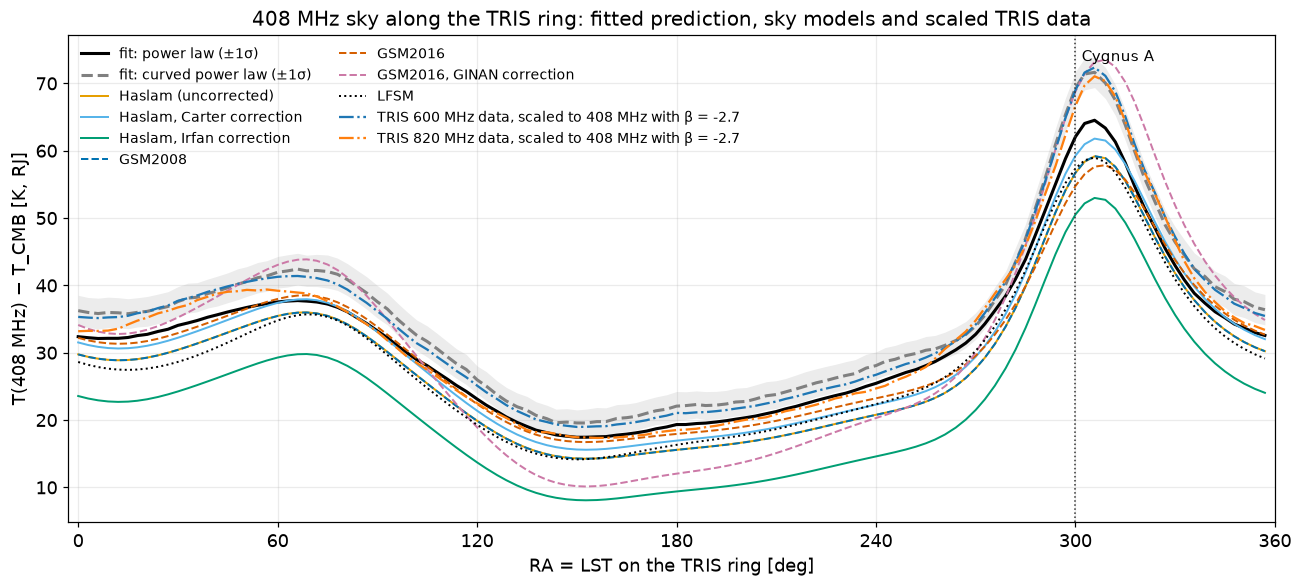

saved model_comparison/sky_models_408/fig1_T408_vs_ra.png


In [5]:
# Measured TRIS rings (CMB-removed RJ, with ring_sigma), as used in the fits; read from the fit cache.
TRIS_STYLE = {"TRIS_600": dict(fmt=".", mfc="white"), "TRIS_820": dict(fmt="x", mfc="0.6")}
tris = {k: (np.full(N_RING, np.nan), np.full(N_RING, np.nan)) for k in TRIS_STYLE}
tris_nu = {}
for u, r in fits[PL].items():
    keys = list(map(str, r["keys"]))
    for k in TRIS_STYLE:
        if k in keys:
            j = keys.index(k)
            tris_nu[k] = float(r["nu"][j])
            f = (408.0 / tris_nu[k]) ** TRIS_BETA          # scale to 408 MHz (errors scale the same)
            tris[k][0][u], tris[k][1][u] = r["t"][j] * f, r["s"][j] * f

fig, ax = plt.subplots(figsize=(12, 5.5))
for m in FITS:
    st = FIT_STYLE[m]
    ax.fill_between(RA, A_best[m] - A_sig[m], A_best[m] + A_sig[m], color=st["color"], alpha=0.15, lw=0)
    ax.plot(RA, A_best[m], color=st["color"], ls=st["ls"], lw=2, label=f"fit: {m} (±1σ)")
for n in SKY_NAMES:
    ax.plot(RA, T_SKY[n], lw=1.3, **SKY_STYLE[n], label=n)
for k, st in TRIS_STYLE.items():
    # ax.errorbar(RA, tris[k][0], yerr=tris[k][1], fmt=st["fmt"], ms=3.5, mfc=st["mfc"], mec="black",
    #             ecolor="black", elinewidth=0.8, capsize=0, zorder=5,
    #             label=f"TRIS {k.split('_')[1]} MHz data, scaled to 408 MHz with β = {TRIS_BETA:g}")
    ax.plot(RA, tris[k][0], ls='-.',
                    label=f"TRIS {k.split('_')[1]} MHz data, scaled to 408 MHz with β = {TRIS_BETA:g}")
ax.axvline(CYG_A_RA, color="0.2", ls=":", lw=1)
ax.text(CYG_A_RA + 2, 0.97, "Cygnus A", transform=ax.get_xaxis_transform(), va="top", fontsize=10)
ax.set_xlim(-3, 360); ax.set_xticks(np.arange(0, 361, 60))
ax.set_xlabel("RA = LST on the TRIS ring [deg]"); ax.set_ylabel("T(408 MHz) − T_CMB [K, RJ]")
ax.legend(ncol=2, fontsize=9, frameon=False, loc="upper left")
ax.grid(alpha=0.25)
ax.set_title("408 MHz sky along the TRIS ring: fitted prediction, sky models and scaled TRIS data")
fig.tight_layout()
save(fig, "fig1_T408_vs_ra")

### Figure 2 — sky model minus fit, per ring sample
Each line is a plain subtraction, sky model minus fitted prediction, in kelvin. The grey band is the
fit's own 1σ, so a line inside it agrees with the fit at that sample.

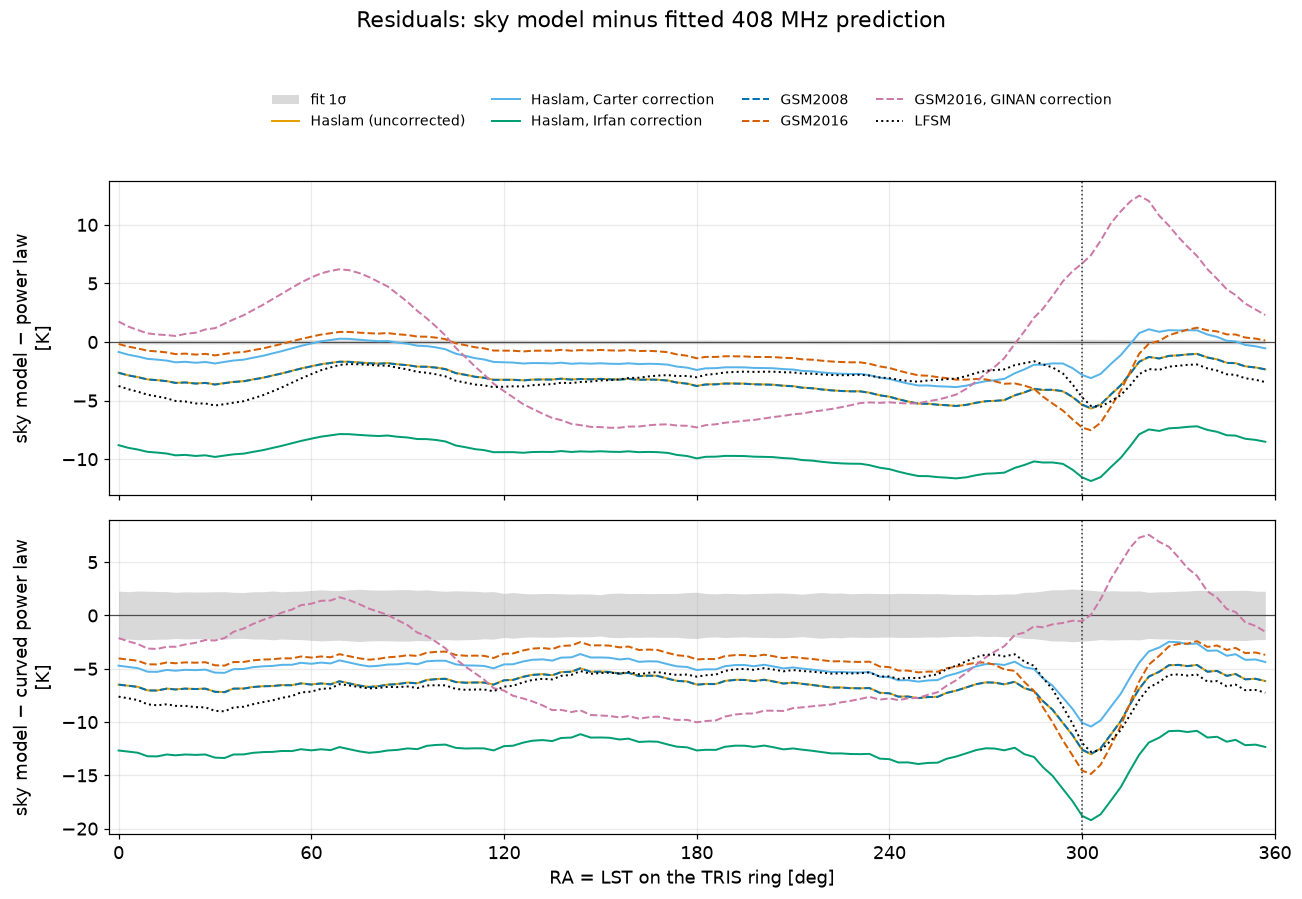

saved model_comparison/sky_models_408/fig2_residual_vs_ra.png


In [6]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
for ax, m in zip(axes, FITS):
    ax.fill_between(RA, -A_sig[m], A_sig[m], color="0.85", lw=0, label=f"fit 1σ")
    ax.axhline(0, color="0.3", lw=0.8)
    for n in SKY_NAMES:
        ax.plot(RA, T_SKY[n] - A_best[m], lw=1.3, **SKY_STYLE[n], label=n)
    ax.axvline(CYG_A_RA, color="0.2", ls=":", lw=1)
    ax.set_ylabel(f"sky model − {m}\n[K]")
    ax.grid(alpha=0.25)
axes[0].legend(ncol=4, fontsize=9, frameon=False, loc="upper center", bbox_to_anchor=(0.5, 1.32))
axes[1].set_xlabel("RA = LST on the TRIS ring [deg]")
axes[1].set_xlim(-3, 360); axes[1].set_xticks(np.arange(0, 361, 60))
fig.suptitle("Residuals: sky model minus fitted 408 MHz prediction", y=1.02)
fig.tight_layout()
save(fig, "fig2_residual_vs_ra")

## 4. χ² for every pair, and the winner

χ² = Σ_k (T_model,k − A_fit,k)² / σ_A,k², over ring samples where both exist; σ_A is the posterior
standard deviation of the fit's 408 MHz temperature. The sky models carry no error of their own here.

In [7]:
rows = []
for m in FITS:
    for n in SKY_NAMES:
        r = T_SKY[n] - A_best[m]
        ok = np.isfinite(r) & np.isfinite(A_sig[m]) & (A_sig[m] > 0)
        chi2 = float(np.sum((r[ok] / A_sig[m][ok]) ** 2))
        rows.append({"fit": m, "sky model": n, "N samples": int(ok.sum()), "chi2": chi2,
                     "chi2 / N": chi2 / ok.sum(),
                     "mean of residual [K]": float(np.mean(r[ok])),
                     "median of residual [K]": float(np.median(r[ok])),
                     "std of residual [K]": float(np.std(r[ok])),
                     "samples within fit 1σ": int(np.sum(np.abs(r[ok]) <= A_sig[m][ok]))})
chi = pd.DataFrame(rows)
chi["rank (per fit)"] = chi.groupby("fit")["chi2"].rank().astype(int)
chi = chi.sort_values(["fit", "chi2"]).reset_index(drop=True)
chi.to_csv(OUT_DIR / "chi2_sky_models_vs_fits.csv", index=False)
print(f"saved {(OUT_DIR / 'chi2_sky_models_vs_fits.csv').relative_to(REPO)}  (best fit = {BEST_FIT})\n")
with pd.option_context("display.width", 200):
    print(chi.round(2).to_string(index=False))

winners = {m: chi[chi["fit"] == m].iloc[0]["sky model"] for m in FITS}
print()
for m in FITS:
    print(f"WINNER against the {m}: {winners[m]}")
if skipped:
    print("\n!! not included:", ", ".join(skipped))

saved model_comparison/sky_models_408/chi2_sky_models_vs_fits.csv  (best fit = maxlike)

             fit                 sky model  N samples      chi2  chi2 / N  mean of residual [K]  median of residual [K]  std of residual [K]  samples within fit 1σ  rank (per fit)
curved power law Haslam, Carter correction        120    650.89      5.42                 -4.92                   -4.73                 1.27                      0               1
curved power law                   GSM2016        120    652.50      5.44                 -4.63                   -4.03                 2.37                      0               2
curved power law GSM2016, GINAN correction        120   1008.26      8.40                 -3.71                   -3.01                 4.74                     40               3
curved power law                      LFSM        120   1131.83      9.43                 -6.57                   -6.23                 1.73                      0               4
curved powe

### Figure 3 — χ² per sample for every pair
Bars show χ²/N, the mean squared residual in units of the fit's σ, for each sky model against each
fit. Shorter is better; the axis is logarithmic because the values span orders of magnitude.

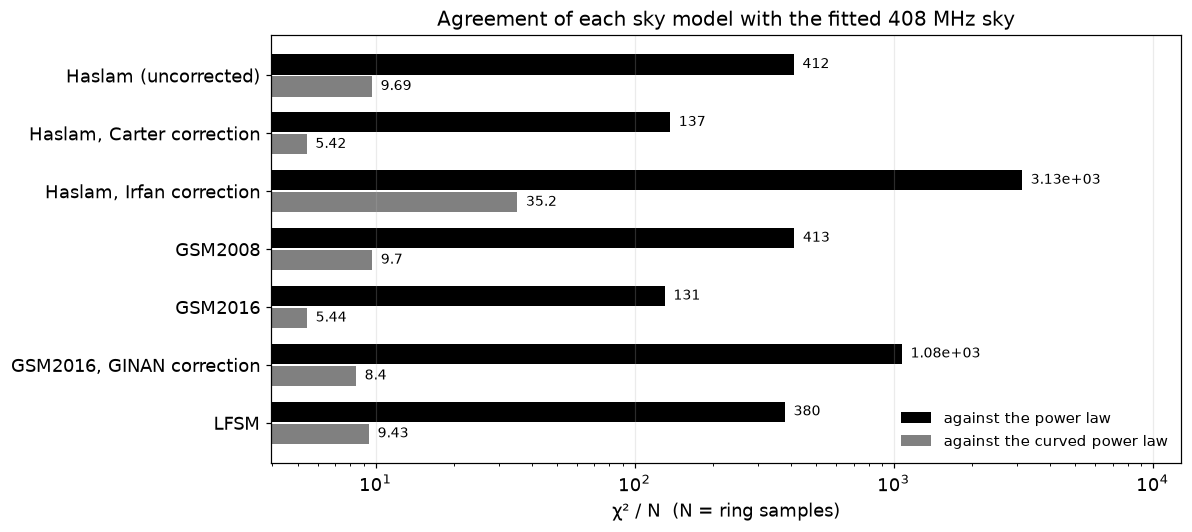

saved model_comparison/sky_models_408/fig3_chi2_per_sample.png


In [8]:
fig, ax = plt.subplots(figsize=(11, 5))
y = np.arange(len(SKY_NAMES))[::-1]
h = 0.38
for j, m in enumerate(FITS):
    sub = chi[chi["fit"] == m].set_index("sky model").loc[SKY_NAMES]
    ax.barh(y + (0.5 - j) * h, sub["chi2 / N"], h * 0.92, color=FIT_STYLE[m]["color"],
            label=f"against the {m}")
    for yi, v in zip(y + (0.5 - j) * h, sub["chi2 / N"]):
        ax.text(v * 1.08, yi, f"{v:.3g}", va="center", fontsize=9)
ax.set_xscale("log")
ax.set_yticks(y); ax.set_yticklabels(SKY_NAMES)
ax.set_xlabel("χ² / N  (N = ring samples)")
ax.legend(frameon=False, loc="lower right")
ax.grid(alpha=0.25, axis="x")
ax.set_xlim(right=ax.get_xlim()[1] * 3)
ax.set_title("Agreement of each sky model with the fitted 408 MHz sky")
fig.tight_layout()
save(fig, "fig3_chi2_per_sample")

## Summary

Results from the run on 2026-10-23: 120 ring samples, best fit = maximum-likelihood A, seed 12345.

* **Winner: GSM2016 and the Carter-corrected Haslam, effectively tied.** Against the power law, GSM2016
  is first (χ²/N 134.0) and Carter second (134.2). Against the curved power law, the order flips:
  Carter first (5.3), GSM2016 second (5.5). The gaps are tiny next to everything else, so no single
  winner can be named between these two.
* **GINAN-corrected GSM2016: right average level, wrong shape.** Its mean residual is the smallest of
  all against the power law (−0.35 K), but its scatter is the largest (std 5.6 K): it is about 6 K too
  bright around RA 70° and 12 K too bright near RA 320°, and about 7 K too faint between RA 130° and
  260°. The 1.53× scale exaggerates the contrast between bright and faint sky. It ranks 6th of 7
  against the power law (χ²/N 1059) and 3rd against the curved power law (8.3). The correction is
  only valid up to 350 MHz; here it is built at 350 MHz and carried to 408 MHz with GSM2016's own
  slope, which is an assumption.
* **Then a cluster, then Irfan.** Uncorrected Haslam, GSM2008 and LFSM sit together (power law χ²/N
  368–408, curved 9.4–9.6). GSM2008 is almost identical to Haslam at 408 MHz, as expected (it is built
  from it). The Irfan correction is last (power law 3108, curved 35). It subtracts the full 8.9 K
  monopole, which includes the radio background that the fitted surveys still contain.
* **Almost every sky model is colder than both fits.** Mean residual (model − fit): −0.4 to −9.4 K
  against the power law, −3.7 to −12.8 K against the curved power law. This is the same deficit the
  TOD route finds for Haslam.
* **χ² mixes the offset and the shape.** Apart from GINAN, the residual scatter (std) is 1.0–2.4 K and
  the mean offsets are larger, so the offset sets the ranking. The power law's σ_A is only 0.17 K, so
  its χ² values are very large; the curved power law's σ_A is 2.2 K, so its χ² values are small. The
  ranking, not the size of χ², is what matters.
* **Caveats.** GSM2008, GSM2016, LFSM (and so GINAN) all use Haslam as an input at 408 MHz, so they are
  not independent of it. The sky models carry no error bars in χ². The Carter and Irfan corrections are
  single whole-sky values, applied to the destriped Haslam map.
